# Figure 3 Supplement 6: Sequential structure in the measured bounds

Do subjects carry their bound over from one trial to the next, beyond what the
stopping model produces? In the model, each trial's bound is drawn
independently around the subject's time course (trial-to-trial variability,
`bound_cv`), so it has no sequential dependence by construction; measurement
noise from the discrete pigeon steps and the model's guesses, lapses and
sensory noise are all included. Each subject's real measured bounds are
compared with the same statistics computed on data simulated from that
subject's fit, on the same trials in the same order, measured with the same
pipeline.

Statistics per subject and block (`pigeon.adaptation.get_sequential_bound_stats`,
on the measured |bound| in trial order):

- **A — Δ|bound| slope:** slope of the regression of the change from one trial
  to the next on the earlier trial's |bound| (−1 = independent trials).
- **B — SD of |bound|** across trials.
- **C — lag-1 autocorrelation** of |bound|.

Each point is a subject: real (ordinate) vs. model (abscissa; mean over
`SIM_REPS` simulated repetitions). P values: Wilcoxon signed-rank test, real
vs. model.

Columns: OL low-SNR blocks 1–3. Trials: the standard filter
(`get_good_trial_array`: DT ≥ 2, trial_number ≥ 10 and the adaptation
exclusion, no wall hit, RT cutoff), finite nonzero bound, raw positions (no
bias correction) for both data and model; subjects need ≥ `MIN_TRIALS` such
trials. Subject-blocks whose plateau sits at a fit limit are left out (counts
printed).

Replaces the old Figure03S04 (archived in `notebooks/archive/`), which used a
fixed-bound simulation as the comparison.

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.adaptation import get_sequential_bound_stats
from pigeon.data import get_good_trial_array
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import (get_plateau_at_limit, get_stopping_model_trials, infer_bounds_like_data,
                             simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

In [2]:
SIM_REPS = 10
SIM_SEED = 13
MIN_TRIALS = 20
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {'B1': 'No penalty', 'B2': 'Coin penalty', 'B3': 'Step penalty'}

trials_all = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[fits.task == 'OL']
sim = simulate_stopping_data_table(trials_all, fits, group_col='condition', num_reps=SIM_REPS,
                                   rng=np.random.default_rng(SIM_SEED))
sim = infer_bounds_like_data(sim)    # keeps each simulated trial's real trial_number

def _measured(t):
    lg = get_good_trial_array(t, min_dt=2) & np.isfinite(t.bound) & (t.bound != 0) & t.condition.isin(BLOCKS)
    return t[lg]

stats_real = get_sequential_bound_stats(_measured(trials_all), group_cols=('subject_index', 'condition'),
                                        min_trials=MIN_TRIALS)
stats_sim = (get_sequential_bound_stats(_measured(sim), group_cols=('subject_index', 'condition', 'rep'),
                                        min_trials=MIN_TRIALS)
             .groupby(level=['subject_index', 'condition']).mean())

at_limit = pd.MultiIndex.from_frame(fits.loc[get_plateau_at_limit(fits), ['subject_index', 'group']])
both = stats_real.join(stats_sim, rsuffix='_model', how='inner')
l_lim = both.index.isin(at_limit)
print(f'excluded {int(l_lim.sum())} subject-blocks with the plateau at a fit limit: {list(both.index[l_lim])}')
both = both[~l_lim]
STATS = [('delta_slope', 'Δ|bound| slope'), ('sd', 'SD of |bound|'), ('lag1_r', 'Lag-1 autocorrelation')]
rows = []
for b in BLOCKS:
    g = both.xs(b, level='condition')
    for col, label in STATS:
        ok = g[[col, col + '_model']].dropna()
        rows.append({'block': b, 'statistic': label, 'subjects': len(ok),
                     'real median': ok[col].median(), 'model median': ok[col + '_model'].median(),
                     'median real − model': (ok[col] - ok[col + '_model']).median(),
                     'Wilcoxon p': scipy.stats.wilcoxon(ok[col], ok[col + '_model']).pvalue})
    n_short = int((stats_real.xs(b, level='condition').n_trials < MIN_TRIALS).sum())
    print(f'{b}: {n_short} subjects with < {MIN_TRIALS} usable trials (no statistics)')
display(pd.DataFrame(rows).round(3))

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


excluded 3 subject-blocks with the plateau at a fit limit: [(51, 'B1'), (51, 'B2'), (59, 'B1')]
B1: 7 subjects with < 20 usable trials (no statistics)
B2: 8 subjects with < 20 usable trials (no statistics)
B3: 12 subjects with < 20 usable trials (no statistics)


,block,statistic,subjects,real median,model median,median real − model,Wilcoxon p
0,B1,Δ|bound| slope,52,-0.967,-1.013,0.050,0.059
1,B1,SD of |bound|,52,0.117,0.124,-0.003,0.274
2,B1,Lag-1 autocorrelation,52,0.033,-0.013,0.050,0.059
3,B2,Δ|bound| slope,52,-0.960,-1.026,0.062,0.009
4,B2,SD of |bound|,52,0.124,0.133,-0.007,0.002
5,B2,Lag-1 autocorrelation,52,0.040,-0.027,0.060,0.009
6,B3,Δ|bound| slope,43,-0.978,-1.031,0.102,0.012
7,B3,SD of |bound|,43,0.119,0.126,-0.005,0.192
8,B3,Lag-1 autocorrelation,43,0.022,-0.031,0.103,0.013


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


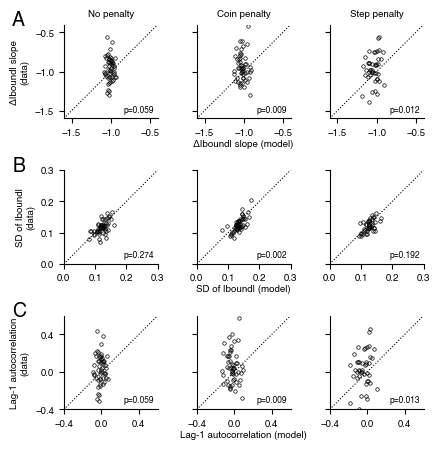

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S06.pdf (+ .png)


In [3]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
LIMITS = {'delta_slope': (-1.6, -0.4), 'sd': (0, 0.3), 'lag1_r': (-0.4, 0.6)}
TICKS = {'delta_slope': [-1.5, -1, -0.5], 'sd': [0, 0.1, 0.2, 0.3], 'lag1_r': [-0.4, 0, 0.4]}

fig = plt.figure(figsize=(11 * CM, 11.5 * CM))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.55, wspace=0.3, left=0.13, right=0.98, bottom=0.08, top=0.93)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(3)])
for c, b in enumerate(BLOCKS):
    g = both.xs(b, level='condition')
    for r, (col, label) in enumerate(STATS):
        ax = axes[r, c]
        ok = g[[col, col + '_model']].dropna()
        lo, hi = LIMITS[col]
        ax.plot([lo, hi], [lo, hi], 'k:', lw=0.8)
        ax.plot(ok[col + '_model'].clip(lo, hi), ok[col].clip(lo, hi), 'ko', mfc='none', ms=2.5, mew=0.5)
        p = scipy.stats.wilcoxon(ok[col], ok[col + '_model']).pvalue
        ax.text(0.96, 0.05, f'p{"<0.001" if p < 0.001 else f"={p:.3f}"}', transform=ax.transAxes,
                ha='right', va='bottom', fontsize=6)
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_xticks(TICKS[col])
        ax.set_yticks(TICKS[col])
        ax.set_box_aspect(1)
        if c > 0:
            ax.set_yticklabels([])
        else:
            ax.set_ylabel(f'{label}\n(data)')
        if r == 0:
            ax.set_title(BLOCK_TITLES[b])
        ax.spines[['top', 'right']].set_visible(False)

def _row_xlabel(axs, label):
    fig.canvas.draw()
    left, right = axs[0].get_position().x0, axs[-1].get_position().x1
    bottom = min(a.get_tightbbox().transformed(fig.transFigure.inverted()).y0 for a in axs)
    fig.text((left + right) / 2, bottom - 0.004, label, ha='center', va='top', fontsize=FS)

for r, (col, label) in enumerate(STATS):
    _row_xlabel(axes[r], f'{label} (model)')
for r, letter in enumerate('ABC'):
    add_panel_label(axes[r, 0], letter, dx=-0.55, dy=1.15)

out = FIGURES_DIR / 'Figure03_S06.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)